# Predicting House Prices in Bangalore
**Project 1: Regression | Major Project, DSBA September 2026 Batch**

Objective: Build a regression model to predict house prices using area, location, and number of rooms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)

print("Libraries ready!")

Libraries ready!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving bengaluru_house_prices.csv to bengaluru_house_prices (1).csv


In [3]:
df = pd.read_csv("/content/bengaluru_house_prices.csv")
print("File loaded successfully!")

File loaded successfully!


## Step 1: Load and Explore the Dataset

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 13320
Columns: 9


In [5]:
df.head(10)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,DuenaTa,1170,2.0,1.0,38.00
6,Super built-up Area,18-May,Old Airport Road,4 BHK,Jaades,2732,4.0,NaN,204.00
7,Super built-up Area,Ready To Move,Rajaji Nagar,4 BHK,Brway G,3300,4.0,NaN,600.00
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,NaN,1310,3.0,1.0,63.25
9,Plot Area,Ready To Move,Gandhi Bazar,6 Bedroom,NaN,1020,6.0,NaN,370.00


In [6]:
print(df.columns.tolist())
print()

df.info()

['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [7]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [8]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent.round(2)
})

missing_table

,Missing Count,Missing %
area_type,0,0.00
availability,0,0.00
location,1,0.01
size,16,0.12
society,5502,41.31
total_sqft,0,0.00
bath,73,0.55
balcony,609,4.57
price,0,0.00


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 529


In [10]:
df.nunique()

,0
area_type,4
availability,81
location,1305
size,31
society,2688
total_sqft,2117
bath,19
balcony,4
price,1994


In [11]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numeric columns:", numeric_cols)
print()
print("Categorical columns:", categorical_cols)

Numeric columns: ['bath', 'balcony', 'price']

Categorical columns: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft']


In [12]:
print("--- area_type ---")
print(df["area_type"].value_counts())

print()
print("--- size ---")
print(df["size"].value_counts().head(10))

print()
print("--- total_sqft (first 15 values) ---")
print(df["total_sqft"].head(15).tolist())

--- area_type ---
area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

--- size ---
size
2 BHK        5199
3 BHK        4310
4 Bedroom     826
4 BHK         591
3 Bedroom     547
1 BHK         538
2 Bedroom     329
5 Bedroom     297
6 Bedroom     191
1 Bedroom     105
Name: count, dtype: int64

--- total_sqft (first 15 values) ---
['1056', '2600', '1440', '1521', '1200', '1170', '2732', '3300', '1310', '1020', '1800', '2785', '1000', '1100', '2250']


In [13]:
def is_number(x):
    try:
        float(x)
        return True
    except:
        return False

bad_rows = df[~df["total_sqft"].apply(is_number)]

print("Rows with non-numeric total_sqft:", len(bad_rows))
bad_rows["total_sqft"].head(15)

Rows with non-numeric total_sqft: 247


,total_sqft
30,2100 - 2850
56,3010 - 3410
81,2957 - 3450
122,3067 - 8156
137,1042 - 1105
165,1145 - 1340
188,1015 - 1540
224,1520 - 1740
410,34.46Sq. Meter
549,1195 - 1440


### Findings from Initial Exploration
- The dataset has 13,320 rows and 9 columns.
- Columns with missing values: society (5,502 missing, 41.31%), balcony (609, 4.57%), bath (73, 0.55%), size (16, 0.12%), location (1, 0.01%)
- Number of duplicate rows: 529
- `total_sqft` is stored as text because it has ranges (e.g. "1133 - 1384") and other units.
- `size` is text (e.g. "2 BHK") and needs to become a number.
- `location` has 1,305 unique values, so it needs special handling.
- `availability` has 81 unique values, so it will be simplified later.
- Prices are in lakhs of rupees.

## Step 2: Data Cleaning and Preprocessing

In [14]:
df2 = df.copy()

print("Rows before cleaning:", len(df2))

Rows before cleaning: 13320


In [15]:
df2 = df2.drop_duplicates()

print("Rows after removing duplicates:", len(df2))

Rows after removing duplicates: 12791


In [16]:
df2 = df2.drop("society", axis=1)

print("Columns now:", df2.columns.tolist())

Columns now: ['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath', 'balcony', 'price']


In [17]:
df2 = df2.dropna(subset=["location", "size"])

print("Rows now:", len(df2))

Rows now: 12774


In [18]:
bath_median = df2["bath"].median()
balcony_median = df2["balcony"].median()

print("Median bath:", bath_median)
print("Median balcony:", balcony_median)

df2["bath"] = df2["bath"].fillna(bath_median)
df2["balcony"] = df2["balcony"].fillna(balcony_median)

Median bath: 2.0
Median balcony: 2.0


In [19]:
print(df2.isnull().sum())

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64


In [20]:
df2["bhk"] = df2["size"].str.split().str[0].astype(int)

print(df2["bhk"].value_counts().sort_index())

bhk
1      638
2     5245
3     4654
4     1398
5      350
6      221
7       99
8       89
9       54
10      14
11       4
12       1
13       1
14       1
16       1
18       1
19       1
27       1
43       1
Name: count, dtype: int64


In [21]:
def convert_sqft(x):
    try:
        return float(x)
    except:
        parts = str(x).split("-")
        if len(parts) == 2:
            try:
                return (float(parts[0]) + float(parts[1])) / 2
            except:
                return np.nan
        return np.nan

df2["total_sqft"] = df2["total_sqft"].apply(convert_sqft)

print("Values that could not be converted:", df2["total_sqft"].isnull().sum())

Values that could not be converted: 46


In [22]:
df2 = df2.dropna(subset=["total_sqft"])

print("Rows now:", len(df2))
print("Data type of total_sqft:", df2["total_sqft"].dtype)

Rows now: 12728
Data type of total_sqft: float64


In [23]:
df2["location"] = df2["location"].str.strip()

print("Unique locations now:", df2["location"].nunique())

Unique locations now: 1287


In [24]:
print("Shape:", df2.shape)
print()
df2.info()
df2.head()

Shape: (12728, 9)

<class 'pandas.core.frame.DataFrame'>
Index: 12728 entries, 0 to 13318
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     12728 non-null  object 
 1   availability  12728 non-null  object 
 2   location      12728 non-null  object 
 3   size          12728 non-null  object 
 4   total_sqft    12728 non-null  float64
 5   bath          12728 non-null  float64
 6   balcony       12728 non-null  float64
 7   price         12728 non-null  float64
 8   bhk           12728 non-null  int64  
dtypes: float64(4), int64(1), object(4)
memory usage: 994.4+ KB


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,1.0,51.00,2


### Cleaning Summary
- Removed 529 duplicate rows (13,320 → 12,791).
- Dropped the `society` column (41.31% missing).
- Dropped 17 rows with missing `location` or `size` (12,791 → 12,774).
- Filled missing `bath` with the median (2.0) and `balcony` with the median (2.0).
- Created a numeric `bhk` column from `size`.
- Converted `total_sqft` to numbers (ranges replaced by their average) and dropped 46 rows that could not be converted (12,774 → 12,728).
- Final dataset has 12,728 rows and 9 columns.

## Step 3: Feature Engineering and Outlier Removal

**Important note:** `price_per_sqft` is calculated from the target (price).
It is used ONLY for outlier detection and EDA. It is NOT used as a model input,
because that would be data leakage (the model would "see" the answer).

In [25]:
df3 = df2.copy()

df3 = df3.reset_index(drop=True)

print("Starting rows for Step 3:", len(df3))

Starting rows for Step 3: 12728


In [26]:
df3["price_per_sqft"] = df3["price"] * 100000 / df3["total_sqft"]

df3[["price", "total_sqft", "price_per_sqft"]].head()

,price,total_sqft,price_per_sqft
0,39.07,1056.0,3699.810606
1,120.00,2600.0,4615.384615
2,62.00,1440.0,4305.555556
3,95.00,1521.0,6245.890861
4,51.00,1200.0,4250.000000


In [27]:
df3[["total_sqft", "bath", "bhk", "price", "price_per_sqft"]].describe()

,total_sqft,bath,bhk,price,price_per_sqft
count,12728.000000,12728.00000,12728.000000,12728.000000,1.272800e+04
mean,1568.765510,2.70396,2.816782,114.228781,8.028596e+03
std,1259.945431,1.35301,1.308978,151.617682,1.086857e+05
min,1.000000,1.00000,1.000000,8.000000,2.678298e+02
25%,1100.000000,2.00000,2.000000,50.000000,4.299055e+03
50%,1280.000000,2.00000,3.000000,73.000000,5.484552e+03
75%,1690.000000,3.00000,3.000000,120.000000,7.400266e+03
max,52272.000000,40.00000,43.000000,3600.000000,1.200000e+07


In [28]:
df_before_outliers = df3.copy()
print("Rows before outlier removal:", len(df_before_outliers))

Rows before outlier removal: 12728


In [29]:
rows_before = len(df3)

df3 = df3[df3["total_sqft"] / df3["bhk"] >= 300]

print("Rows before:", rows_before)
print("Rows after: ", len(df3))
print("Removed:    ", rows_before - len(df3))

Rows before: 12728
Rows after:  11994
Removed:     734


In [30]:
rows_before = len(df3)

df3 = df3[df3["bath"] <= df3["bhk"] + 2]

print("Rows before:", rows_before)
print("Rows after: ", len(df3))
print("Removed:    ", rows_before - len(df3))

Rows before: 11994
Rows after:  11985
Removed:     9


In [31]:
def remove_pps_outliers(data):
    kept = []
    for loc, group in data.groupby("location"):
        avg = group["price_per_sqft"].mean()
        std = group["price_per_sqft"].std()

        if pd.isna(std):
            kept.append(group)
        else:
            good = group[(group["price_per_sqft"] > avg - std) &
                         (group["price_per_sqft"] <= avg + std)]
            kept.append(good)
    return pd.concat(kept, ignore_index=True)

rows_before = len(df3)
df3 = remove_pps_outliers(df3)

print("Rows before:", rows_before)
print("Rows after: ", len(df3))
print("Removed:    ", rows_before - len(df3))

Rows before: 11985
Rows after:  9643
Removed:     2342


In [32]:
def remove_bhk_outliers(data):
    drop_index = np.array([])
    for loc, loc_group in data.groupby("location"):
        bhk_stats = {}
        for bhk, bhk_group in loc_group.groupby("bhk"):
            bhk_stats[bhk] = {
                "mean": bhk_group["price_per_sqft"].mean(),
                "count": bhk_group.shape[0]
            }
        for bhk, bhk_group in loc_group.groupby("bhk"):
            lower = bhk_stats.get(bhk - 1)
            if lower and lower["count"] > 5:
                bad = bhk_group[bhk_group["price_per_sqft"] < lower["mean"]].index.values
                drop_index = np.append(drop_index, bad)
    return data.drop(drop_index, axis="index")

rows_before = len(df3)
df3 = remove_bhk_outliers(df3)
df3 = df3.reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after: ", len(df3))
print("Removed:    ", rows_before - len(df3))

Rows before: 9643
Rows after:  7977
Removed:     1666


In [33]:
print("Rows before all outlier removal:", len(df_before_outliers))
print("Rows after all outlier removal: ", len(df3))
print("Total removed:", len(df_before_outliers) - len(df3))
print()
df3[["total_sqft", "bath", "bhk", "price", "price_per_sqft"]].describe()

Rows before all outlier removal: 12728
Rows after all outlier removal:  7977
Total removed: 4751



,total_sqft,bath,bhk,price,price_per_sqft
count,7977.000000,7977.000000,7977.000000,7977.000000,7977.000000
mean,1528.914535,2.485396,2.547198,103.265917,6145.319945
std,986.442134,1.046592,0.965327,123.326981,2971.253455
min,300.000000,1.000000,1.000000,10.000000,729.860414
25%,1100.000000,2.000000,2.000000,50.000000,4444.444444
50%,1265.000000,2.000000,2.000000,70.000000,5500.000000
75%,1685.000000,3.000000,3.000000,110.000000,6762.716848
max,30400.000000,16.000000,16.000000,2912.000000,37500.000000


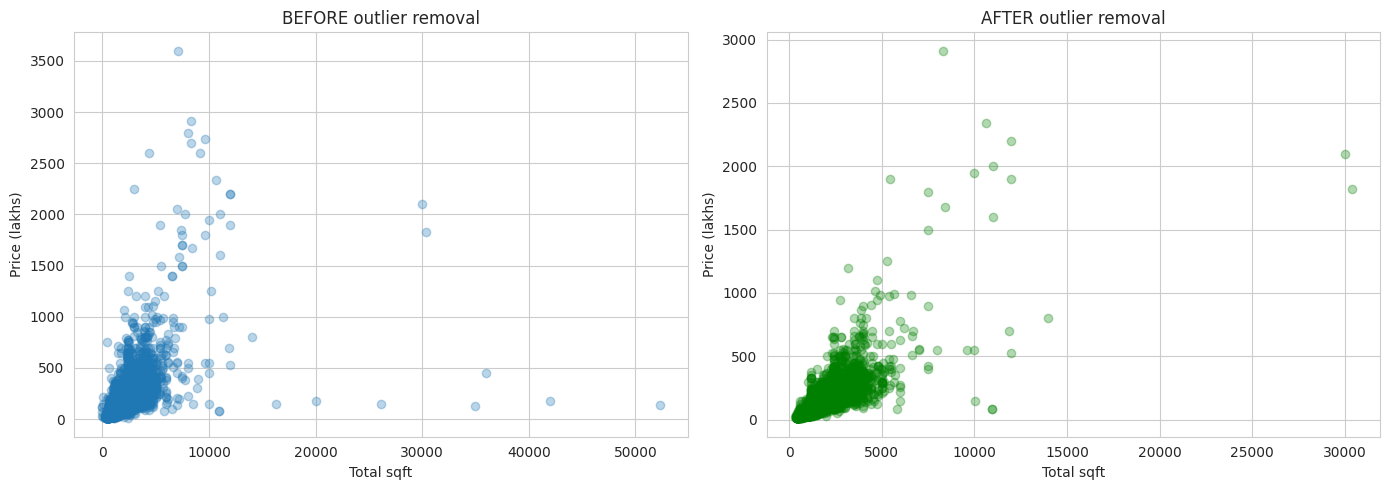

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df_before_outliers["total_sqft"], df_before_outliers["price"], alpha=0.3)
axes[0].set_title("BEFORE outlier removal")
axes[0].set_xlabel("Total sqft")
axes[0].set_ylabel("Price (lakhs)")

axes[1].scatter(df3["total_sqft"], df3["price"], alpha=0.3, color="green")
axes[1].set_title("AFTER outlier removal")
axes[1].set_xlabel("Total sqft")
axes[1].set_ylabel("Price (lakhs)")

plt.tight_layout()
plt.show()

### Outlier Removal Summary
- Rule 1 (sqft per bedroom below 300): removed 734 rows.
- Rule 2 (bathrooms more than bhk + 2): removed 9 rows.
- Rule 3 (price per sqft outside 1 std within a location): removed 2,342 rows.
- Rule 4 (a larger BHK cheaper per sqft than a smaller one in the same location): removed 1,666 rows.
- Rows went from 12,728 to 7,977 (4,751 removed in total, about 37%).
- Insight: Before cleaning, listings reached 52,000 sqft with prices that did not match their size. After removal the price vs. area relationship is much tighter and mostly increasing, so a model can learn it more easily.

In [35]:
df3.sort_values("total_sqft", ascending=False)[
    ["location", "total_sqft", "bhk", "bath", "price", "price_per_sqft"]
].head(10)

,location,total_sqft,bhk,bath,price,price_per_sqft
2104,Dodsworth Layout,30400.0,6,4.0,1824.0,6000.000000
2097,Dodsworth Layout,30000.0,4,4.0,2100.0,7000.000000
6673,Siddapura,14000.0,4,3.0,800.0,5714.285714
3864,Jp nagar 8th Phase .,12000.0,10,12.0,525.0,4375.000000
5044,Malleshwaram,12000.0,7,7.0,2200.0,18333.333333
7895,Yemlur,12000.0,8,9.0,1900.0,15833.333333
7516,Whitefield,11890.0,4,4.0,700.0,5887.300252
7896,Yemlur,11000.0,4,5.0,2000.0,18181.818182
1834,Church Street,11000.0,4,4.0,1600.0,14545.454545
86,4 Bedroom Farm House in Bagalur,10961.0,4,4.0,80.0,729.860414


In [36]:
df3[df3["bhk"] >= 8][["location", "total_sqft", "bhk", "bath", "price"]]

,location,total_sqft,bhk,bath,price
0,1 Giri Nagar,5000.0,11,9.0,360.0
1,1 Immadihalli,6000.0,11,12.0,150.0
4,1Hoysalanagar,5425.0,13,13.0,275.0
92,4th Block Koramangala,4500.0,9,9.0,500.0
347,Abbigere,3000.0,8,8.0,150.0
1422,Bommanahalli,3000.0,8,8.0,140.0
1773,Chikkabanavar,4000.0,8,7.0,110.0
2045,Doddabommasandra,3150.0,8,5.0,145.0
2160,Dwarka Nagar,2400.0,8,6.0,125.0
2573,Gnana Bharathi,3200.0,9,8.0,130.0


In [37]:
df4 = df3.copy()

rows_before = len(df4)

df4 = df4[df4["total_sqft"] <= 10000]
print("After removing sqft above 10000:", len(df4), "| removed:", rows_before - len(df4))

rows_mid = len(df4)
df4 = df4[df4["bhk"] <= 10]
print("After removing bhk above 10:   ", len(df4), "| removed:", rows_mid - len(df4))

df4 = df4.reset_index(drop=True)
print("Final rows:", len(df4))

After removing sqft above 10000: 7964 | removed: 13
After removing bhk above 10:    7960 | removed: 4
Final rows: 7960


In [38]:
df4[["total_sqft", "bath", "bhk", "price", "price_per_sqft"]].describe()

,total_sqft,bath,bhk,price,price_per_sqft
count,7960.000000,7960.000000,7960.000000,7960.000000,7960.000000
mean,1505.384453,2.476256,2.538191,101.271133,6140.715668
std,783.798470,1.010779,0.928557,108.991783,2957.255289
min,300.000000,1.000000,1.000000,10.000000,1250.000000
25%,1100.000000,2.000000,2.000000,50.000000,4444.444444
50%,1265.000000,2.000000,2.000000,70.000000,5500.000000
75%,1680.000000,3.000000,3.000000,110.000000,6761.519797
max,10000.000000,12.000000,10.000000,2912.000000,37500.000000


### Final Outlier Limits
- Removed 13 homes above 10,000 sqft (data entry errors such as 30,000 sqft with 4 bedrooms).
- Removed 4 homes with more than 10 bedrooms (likely PGs, hostels or typos).
- Kept high-priced luxury homes, because they look like real listings, not errors.
- Rows went from 7,977 to 7,960.

In [39]:
print("Unique locations before:", df4["location"].nunique())

df4["location"] = df4["location"].str.strip().str.rstrip(" .")

print("Unique locations after: ", df4["location"].nunique())

Unique locations before: 1193
Unique locations after:  1193


In [40]:
location_counts = df4["location"].value_counts()

print("Locations with 10 or fewer listings:", (location_counts <= 10).sum())
print("Locations with more than 10 listings:", (location_counts > 10).sum())
print()
location_counts.head(10)

Locations with 10 or fewer listings: 1024
Locations with more than 10 listings: 169



,count
location,
Whitefield,239
Sarjapur Road,174
Electronic City,157
Raja Rajeshwari Nagar,129
Marathahalli,111
Bannerghatta Road,107
Thanisandra,106
Hennur Road,106
Uttarahalli,106


In [41]:
rare_locations = location_counts[location_counts <= 10].index

df4["location"] = df4["location"].apply(lambda x: "other" if x in rare_locations else x)

print("Unique locations now:", df4["location"].nunique())
print()
print(df4["location"].value_counts().head(8))

Unique locations now: 170

location
other                    2560
Whitefield                239
Sarjapur  Road            174
Electronic City           157
Raja Rajeshwari Nagar     129
Marathahalli              111
Bannerghatta Road         107
Uttarahalli               106
Name: count, dtype: int64


In [42]:
df4["availability"] = np.where(df4["availability"] == "Ready To Move",
                               "Ready To Move", "Not Ready")

print(df4["availability"].value_counts())

availability
Ready To Move    6343
Not Ready        1617
Name: count, dtype: int64


In [43]:
num_check = ["total_sqft", "bath", "balcony", "bhk", "price", "price_per_sqft"]
print(df4[num_check].skew().round(2))

total_sqft        2.84
bath              1.95
balcony          -0.01
bhk               1.72
price             7.06
price_per_sqft    3.07
dtype: float64


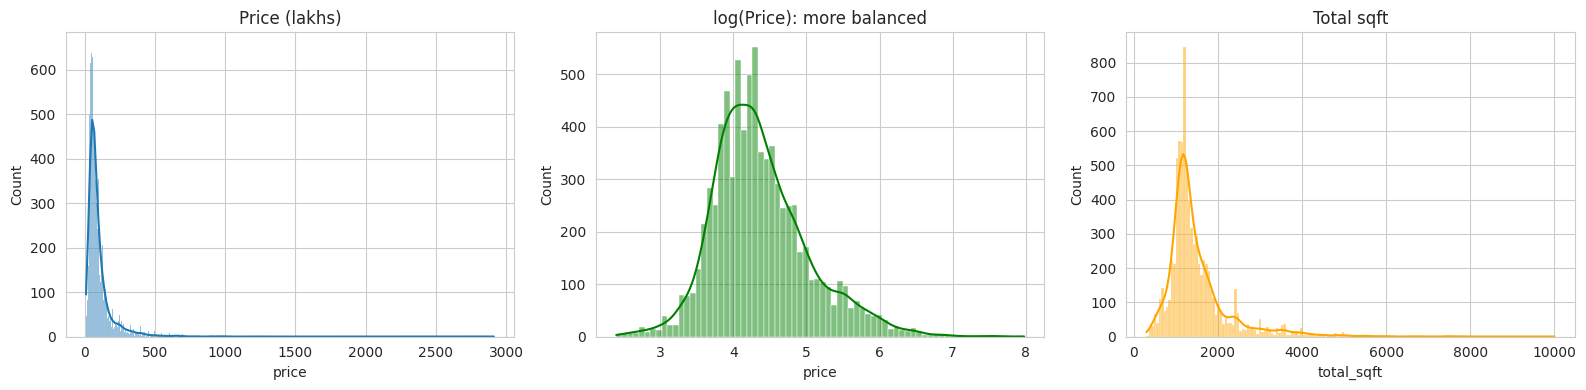

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df4["price"], kde=True, ax=axes[0])
axes[0].set_title("Price (lakhs)")

sns.histplot(np.log1p(df4["price"]), kde=True, ax=axes[1], color="green")
axes[1].set_title("log(Price): more balanced")

sns.histplot(df4["total_sqft"], kde=True, ax=axes[2], color="orange")
axes[2].set_title("Total sqft")

plt.tight_layout()
plt.show()

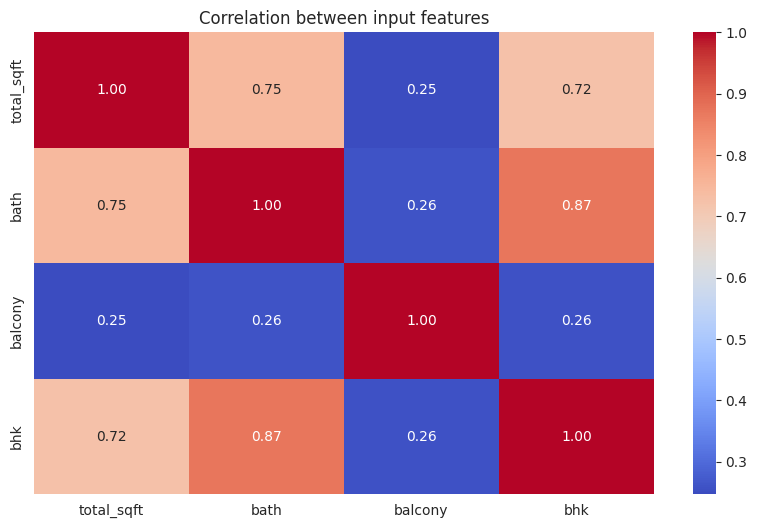

In [45]:
sns.heatmap(df4[["total_sqft", "bath", "balcony", "bhk"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between input features")
plt.show()

In [46]:
df4 = df4.drop("size", axis=1)

print(df4.columns.tolist())
print("Shape:", df4.shape)

['area_type', 'availability', 'location', 'total_sqft', 'bath', 'balcony', 'price', 'bhk', 'price_per_sqft']
Shape: (7960, 9)


### Feature Engineering Summary
- Created `price_per_sqft` (used for outlier detection and EDA only, never as a model input, to avoid data leakage).
- Grouped locations with 10 or fewer listings into "other": 1,024 locations merged into one category, reducing 1,193 unique locations to 170.
- Simplified `availability` from 81 values to 2 (Ready To Move / Not Ready).
- Dropped `size` because `bhk` replaces it.
- Skewness: price skew = 7.06, total_sqft skew = 2.84 (both strongly right-skewed). A log version of price will be tested in modelling.
- bhk and bath have a correlation of 0.87 (highly correlated). Both are kept because tree models handle this well, and Ridge/Lasso will be compared for the linear model.
- Final dataset has 7,960 rows and 9 columns.

## Step 4: Exploratory Data Analysis (EDA)
Below I explore how price relates to area, BHK, bathrooms, area type, availability and location.

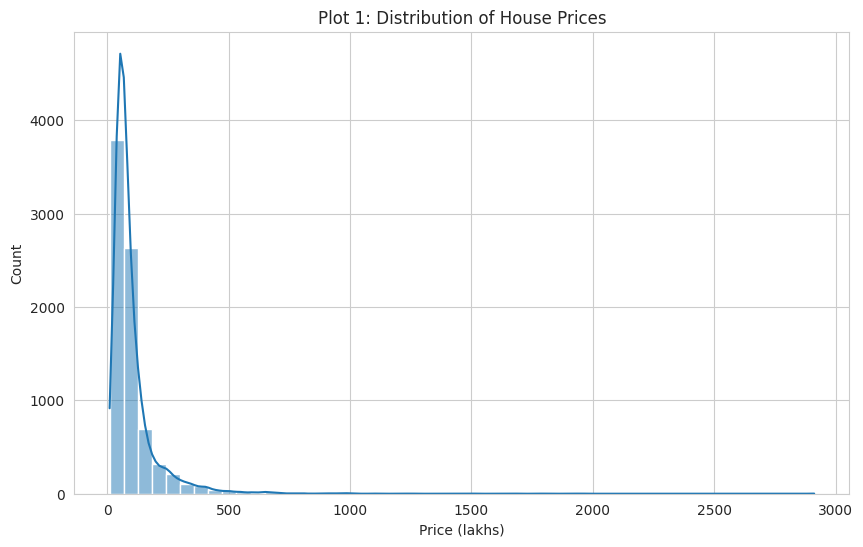

In [47]:
sns.histplot(df4["price"], kde=True, bins=50)
plt.title("Plot 1: Distribution of House Prices")
plt.xlabel("Price (lakhs)")
plt.show()

**Plot 1 insight:** Most homes cost under about 150 lakhs, but a few luxury listings stretch the tail out to nearly 3,000 lakhs. This heavy right skew (7.06) is why a log transform of price will be tested.

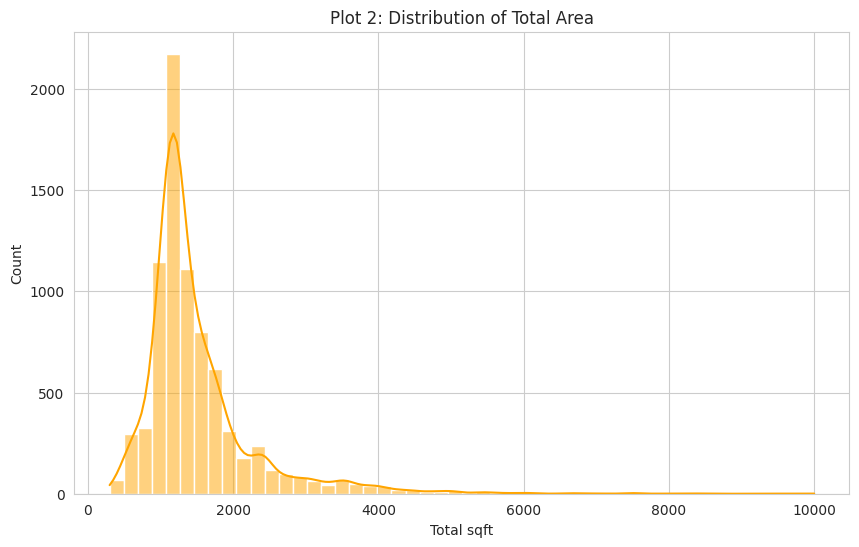

In [48]:
sns.histplot(df4["total_sqft"], kde=True, bins=50, color="orange")
plt.title("Plot 2: Distribution of Total Area")
plt.xlabel("Total sqft")
plt.show()

**Plot 2 insight:** Most homes are between 1,000 and 2,000 sqft, with a peak near 1,200 sqft. Larger homes are rare, so the area distribution is also right-skewed (2.84).


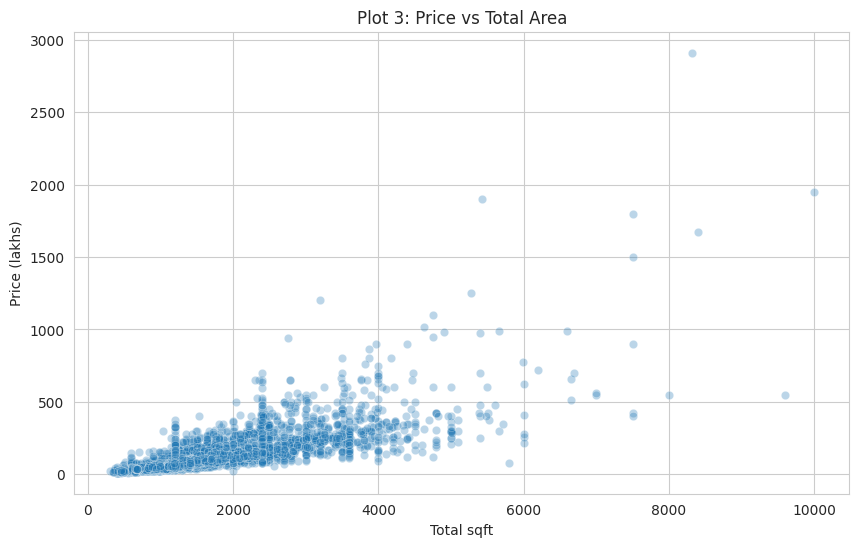

In [49]:
sns.scatterplot(data=df4, x="total_sqft", y="price", alpha=0.3)
plt.title("Plot 3: Price vs Total Area")
plt.xlabel("Total sqft")
plt.ylabel("Price (lakhs)")
plt.show()

**Plot 3 insight:** Price rises with area, but the spread widens as homes get bigger. At the same size, prices can differ a lot, which shows that area alone cannot explain price and location must matter.

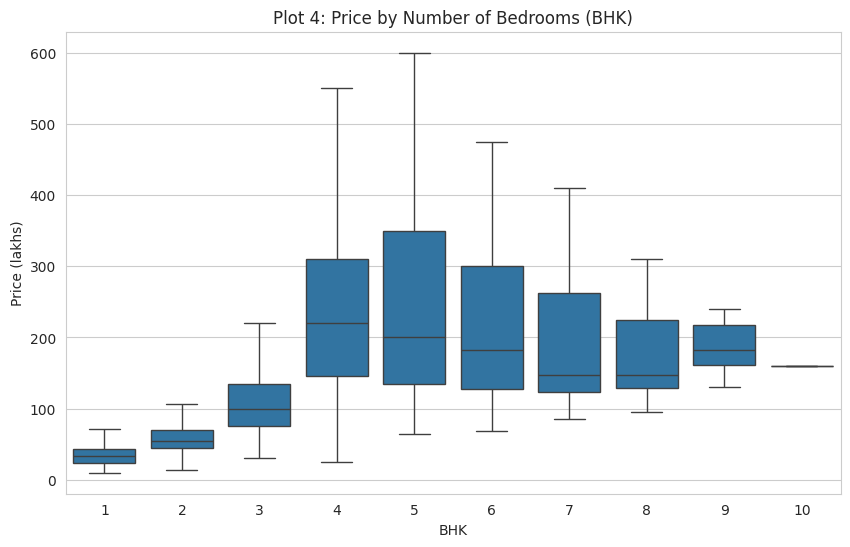

In [50]:
sns.boxplot(data=df4, x="bhk", y="price", showfliers=False)
plt.title("Plot 4: Price by Number of Bedrooms (BHK)")
plt.xlabel("BHK")
plt.ylabel("Price (lakhs)")
plt.show()

**Plot 4 insight:** Median price climbs from about 35 lakhs (1 BHK) to about 220 lakhs (4 BHK). Beyond 4 BHK it levels off and then dips, and the boxes get very wide. This is because large-BHK listings are few and vary a lot, so BHK is not a straight-line predictor at the top end.

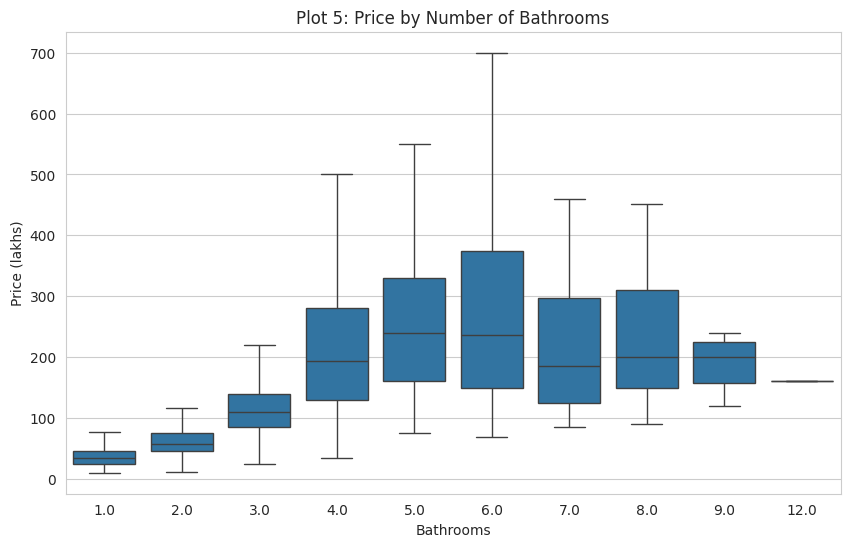

In [51]:
sns.boxplot(data=df4, x="bath", y="price", showfliers=False)
plt.title("Plot 5: Price by Number of Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Price (lakhs)")
plt.show()

**Plot 5 insight:** Bathrooms follow the same pattern as BHK: price rises up to about 4-6 bathrooms and then stops increasing. This matches the 0.87 correlation between bath and bhk.

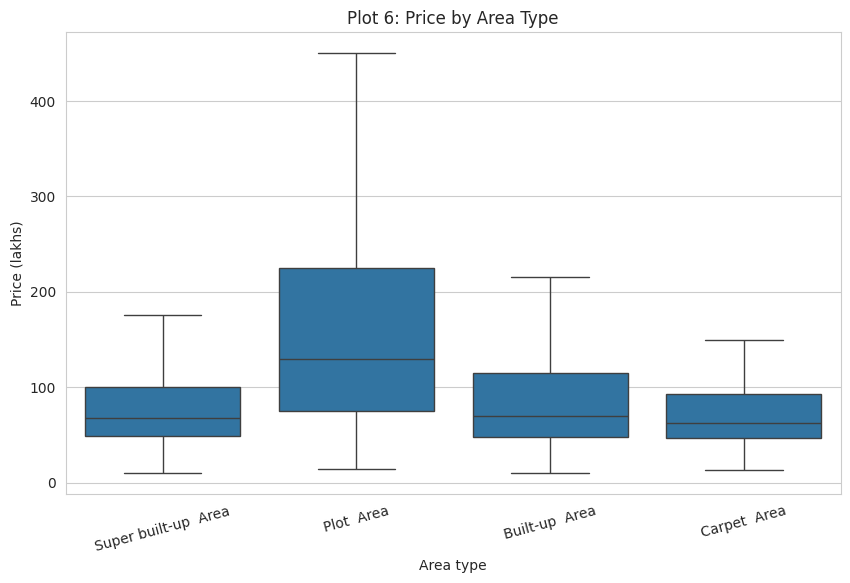

In [52]:
sns.boxplot(data=df4, x="area_type", y="price", showfliers=False)
plt.title("Plot 6: Price by Area Type")
plt.xlabel("Area type")
plt.ylabel("Price (lakhs)")
plt.xticks(rotation=15)
plt.show()

**Plot 6 insight:** Plot Area homes have the highest median price (about 130 lakhs) and the widest spread. Super built-up, Built-up and Carpet Area homes have similar medians (about 60-70 lakhs).

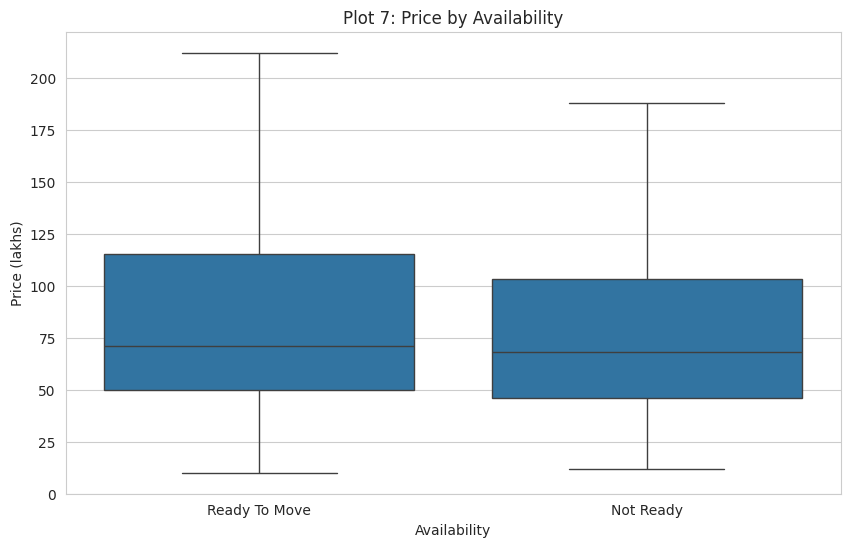

In [53]:
sns.boxplot(data=df4, x="availability", y="price", showfliers=False)
plt.title("Plot 7: Price by Availability")
plt.xlabel("Availability")
plt.ylabel("Price (lakhs)")
plt.show()

**Plot 7 insight:** Ready To Move and Not Ready homes have almost the same median price (about 70 lakhs), so availability has little effect on price.

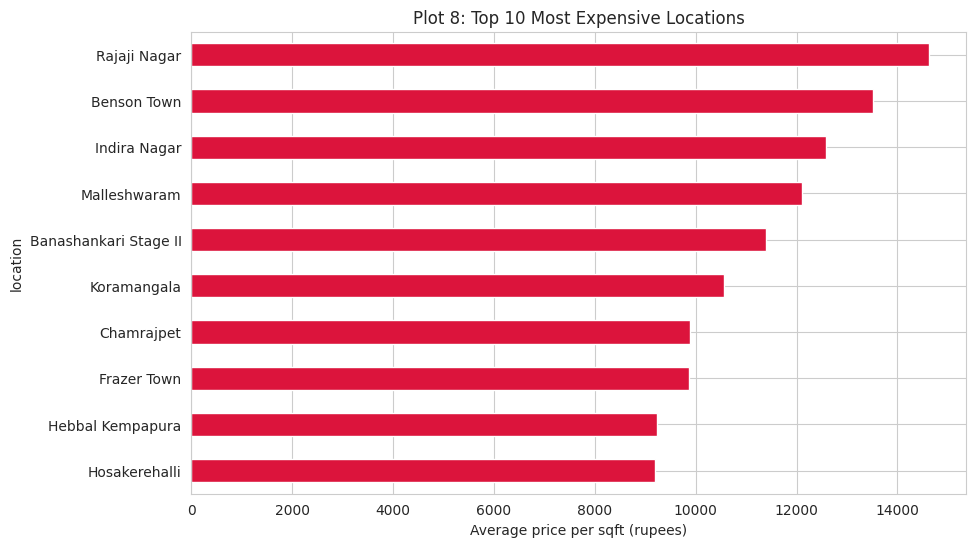

In [54]:
real_locs = df4[df4["location"] != "other"]

top_expensive = (real_locs.groupby("location")["price_per_sqft"]
                 .mean().sort_values(ascending=False).head(10))

top_expensive.sort_values().plot(kind="barh", color="crimson")
plt.title("Plot 8: Top 10 Most Expensive Locations")
plt.xlabel("Average price per sqft (rupees)")
plt.show()

**Plot 8 insight:** Rajaji Nagar, Benson Town, Indira Nagar and Malleshwaram are the priciest areas, at about 12,000 to 14,600 rupees per sqft. These are central, established parts of the city, so location clearly drives price.

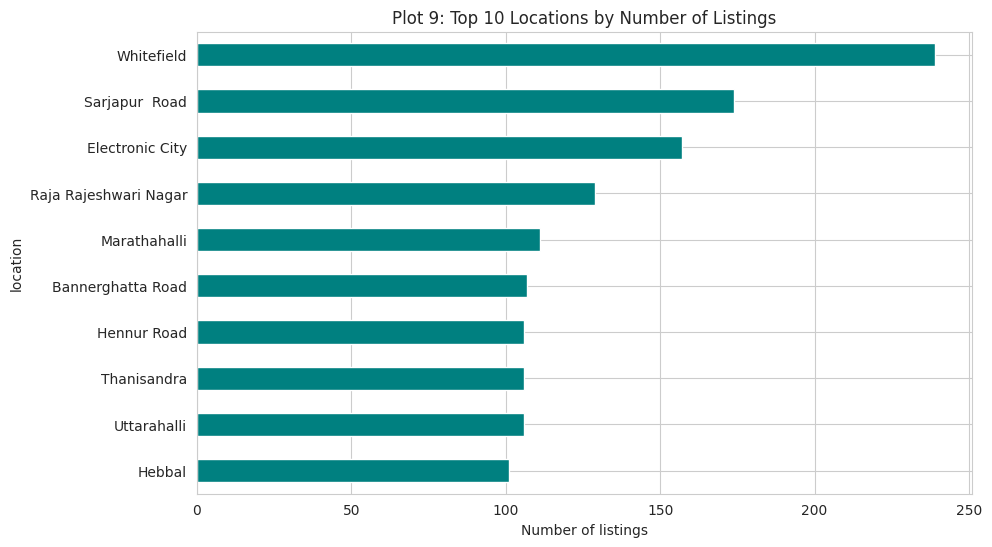

In [55]:
top_listed = real_locs["location"].value_counts().head(10)

top_listed.sort_values().plot(kind="barh", color="teal")
plt.title("Plot 9: Top 10 Locations by Number of Listings")
plt.xlabel("Number of listings")
plt.show()

**Plot 9 insight:** Whitefield has the most listings (about 239), followed by Sarjapur Road and Electronic City. The most-listed areas are largely the IT corridors on the city's edges, and none of them is in the top 10 most expensive list.

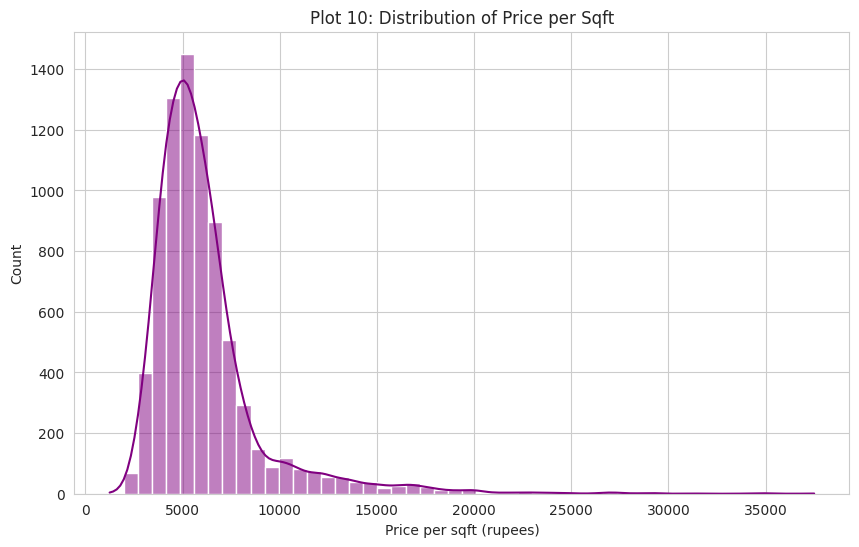

In [56]:
sns.histplot(df4["price_per_sqft"], kde=True, bins=50, color="purple")
plt.title("Plot 10: Distribution of Price per Sqft")
plt.xlabel("Price per sqft (rupees)")
plt.show()

**Plot 10 insight:** Most homes cost between 4,000 and 7,000 rupees per sqft, with a peak near 5,000. A thin right tail goes up to 37,500, so price per sqft is also right-skewed (3.07).

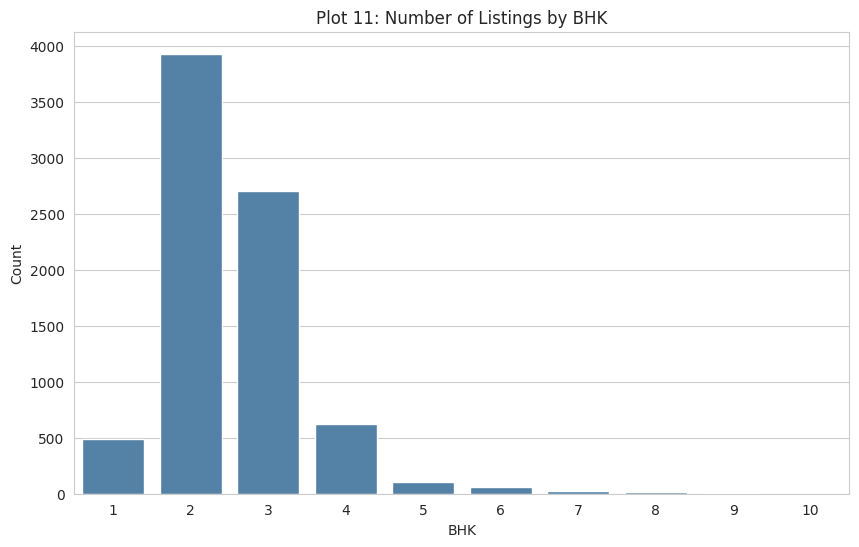

In [57]:
sns.countplot(data=df4, x="bhk", color="steelblue")
plt.title("Plot 11: Number of Listings by BHK")
plt.xlabel("BHK")
plt.ylabel("Count")
plt.show()

**Plot 11 insight:** 2 BHK (about 3,900) and 3 BHK (about 2,700) homes make up the vast majority of listings. Homes with 5 or more BHK are very rare, so the model will have little data to learn them from

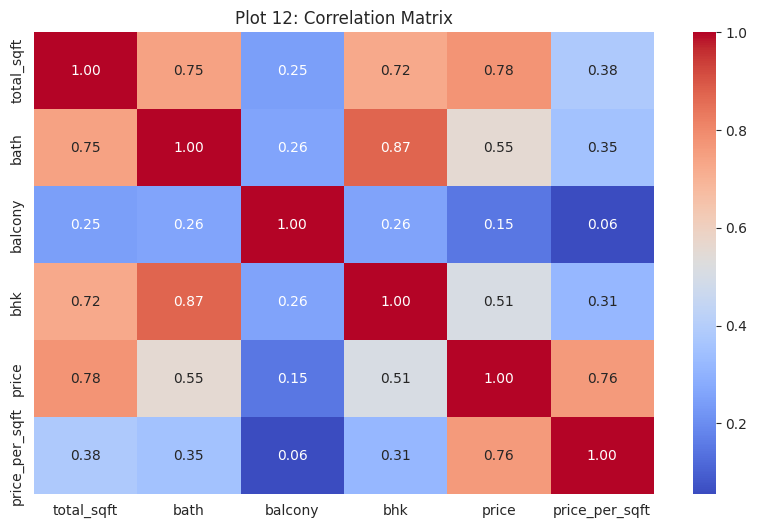

In [58]:
num_cols_eda = ["total_sqft", "bath", "balcony", "bhk", "price", "price_per_sqft"]

sns.heatmap(df4[num_cols_eda].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Plot 12: Correlation Matrix")
plt.show()

**Plot 12 insight:** total_sqft has the strongest correlation with price (0.78), followed by bath (0.55) and bhk (0.51). balcony is the weakest (0.15). price_per_sqft correlates at 0.76 but is excluded from modelling because it is calculated from price.

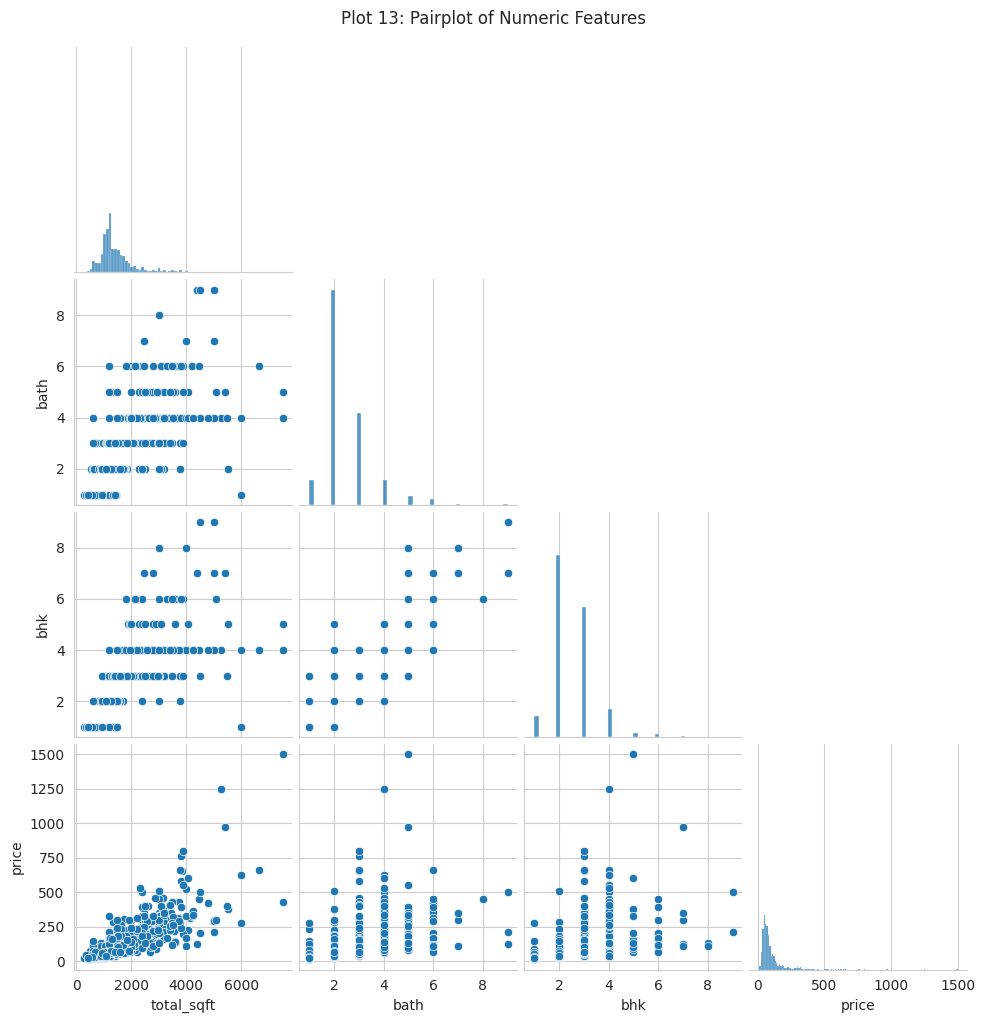

In [59]:
sample = df4[["total_sqft", "bath", "bhk", "price"]].sample(1500, random_state=42)

sns.pairplot(sample, corner=True)
plt.suptitle("Plot 13: Pairplot of Numeric Features", y=1.02)
plt.show()

**Plot 13 insight:** Price rises with total_sqft in a roughly upward trend but fans out at larger sizes. bath and bhk take only a few whole values, so they show up as horizontal bands.

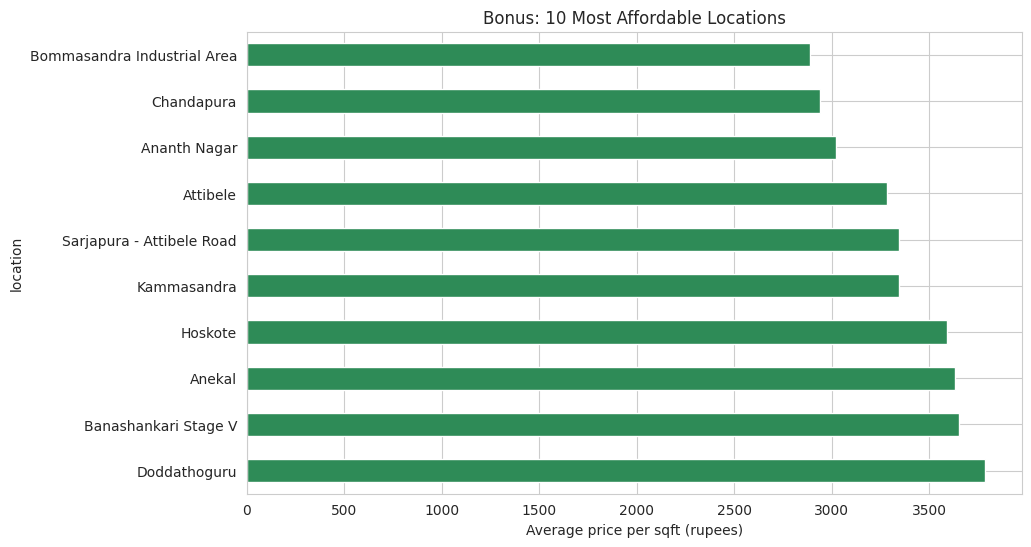

In [60]:
top_cheap = (real_locs.groupby("location")["price_per_sqft"]
             .mean().sort_values().head(10))

top_cheap.sort_values(ascending=False).plot(kind="barh", color="seagreen")
plt.title("Bonus: 10 Most Affordable Locations")
plt.xlabel("Average price per sqft (rupees)")
plt.show()

**Bonus insight:** The cheapest areas (Bommasandra Industrial Area, Chandapura, Ananth Nagar) average about 2,900 to 3,800 rupees per sqft, roughly a quarter of Rajaji Nagar's price. Most of them are on the outskirts of the city.

## Step 5: Model Building
Target: `price` (lakhs). Features: total_sqft, bath, balcony, bhk, location, area_type, availability.
`price_per_sqft` is NOT used (data leakage).

In [61]:
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
print("Modelling tools ready!")

Modelling tools ready!


In [62]:
feature_cols = ["total_sqft", "bath", "balcony", "bhk",
                "location", "area_type", "availability"]

X = df4[feature_cols]
y = df4["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (7960, 7)
y shape: (7960,)


,total_sqft,bath,balcony,bhk,location,area_type,availability
0,1800.0,1.0,1.0,1,other,Super built-up Area,Ready To Move
1,2360.0,4.0,1.0,4,other,Plot Area,Ready To Move
2,1540.0,3.0,2.0,3,other,Super built-up Area,Ready To Move
3,1800.0,5.0,1.0,4,other,Built-up Area,Ready To Move
4,600.0,1.0,0.0,1,other,Super built-up Area,Ready To Move


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))

Training rows: 6368
Testing rows:  1592


In [64]:
num_cols = ["total_sqft", "bath", "balcony", "bhk"]
cat_cols = ["location", "area_type", "availability"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
print("Preprocessor ready")

Preprocessor ready


In [65]:
results = []

def evaluate_model(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)

    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    mae = mean_absolute_error(y_test, test_pred)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()

    results.append({
        "Model": name,
        "Train R2": round(r2_score(y_train, train_pred), 3),
        "Test R2": round(r2_score(y_test, test_pred), 3),
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "CV R2": round(cv, 3)
    })
    print(name, "done")
    return pipe

In [66]:
lr_pipe = evaluate_model("Linear Regression", LinearRegression())
dt_pipe = evaluate_model("Decision Tree", DecisionTreeRegressor(random_state=RANDOM_STATE))
rf_pipe = evaluate_model("Random Forest", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))

Linear Regression done
Decision Tree done
Random Forest done


In [67]:
ridge_pipe = evaluate_model("Ridge", Ridge(alpha=1.0))
lasso_pipe = evaluate_model("Lasso", Lasso(alpha=0.1))
gb_pipe = evaluate_model("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE))

Ridge done
Lasso done
Gradient Boosting done


In [68]:
results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False)
results_df.reset_index(drop=True)

,Model,Train R2,Test R2,RMSE,MAE,CV R2
0,Gradient Boosting,0.812,0.734,51.15,23.85,0.671
1,Random Forest,0.938,0.734,51.18,21.80,0.672
2,Ridge,0.659,0.690,55.22,27.57,0.658
3,Linear Regression,0.659,0.689,55.29,27.66,0.658
4,Lasso,0.650,0.684,55.69,28.18,0.651
5,Decision Tree,0.983,0.387,77.62,28.00,0.542


### Model Comparison Results
- Gradient Boosting and Random Forest are the best models (Test R² = 0.734, RMSE ≈ 51 lakhs).
- Random Forest has the lowest MAE (21.80 lakhs); Gradient Boosting is less overfit (train R² 0.812 vs 0.938).
- Linear, Ridge and Lasso score about 0.68-0.69, so tree-based models capture non-linear patterns (e.g. price flattening beyond 4 BHK) better.
- Decision Tree strongly overfits: train R² 0.983 vs test R² 0.387.
- Ridge gives almost the same result as Linear Regression, so multicollinearity (bhk vs bath = 0.87) did not hurt much.
- Test R² (0.734) is above CV R² (0.672), so CV is the more conservative estimate of real performance.

In [69]:
from sklearn.compose import TransformedTargetRegressor

def evaluate_model_log(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    log_model = TransformedTargetRegressor(
        regressor=pipe, func=np.log1p, inverse_func=np.expm1
    )
    log_model.fit(X_train, y_train)

    train_pred = log_model.predict(X_train)
    test_pred = log_model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    mae = mean_absolute_error(y_test, test_pred)
    cv = cross_val_score(log_model, X_train, y_train, cv=5, scoring="r2").mean()

    results.append({
        "Model": name + " (log price)",
        "Train R2": round(r2_score(y_train, train_pred), 3),
        "Test R2": round(r2_score(y_test, test_pred), 3),
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "CV R2": round(cv, 3)
    })
    print(name, "(log price) done")
    return log_model

In [70]:
lr_log = evaluate_model_log("Linear Regression", LinearRegression())
rf_log = evaluate_model_log("Random Forest", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
gb_log = evaluate_model_log("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE))

Linear Regression (log price) done
Random Forest (log price) done
Gradient Boosting (log price) done


In [71]:
results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False)
results_df.reset_index(drop=True)

,Model,Train R2,Test R2,RMSE,MAE,CV R2
0,Random Forest,0.938,0.734,51.18,21.80,0.672
1,Gradient Boosting,0.812,0.734,51.15,23.85,0.671
2,Random Forest (log price),0.920,0.717,52.74,21.69,0.675
3,Ridge,0.659,0.690,55.22,27.57,0.658
4,Linear Regression,0.659,0.689,55.29,27.66,0.658
5,Lasso,0.650,0.684,55.69,28.18,0.651
6,Gradient Boosting (log price),0.688,0.674,56.64,23.03,0.634
7,Linear Regression (log price),-0.353,0.466,72.44,26.80,-0.699
8,Decision Tree,0.983,0.387,77.62,28.00,0.542


### Log-Price Experiment
- Price is heavily skewed (7.06), so models were also trained on log(price) and predictions converted back to lakhs for a fair comparison.
- Random Forest (log): Test R² 0.717 vs 0.734 (raw). MAE and CV R² were almost identical (21.69 vs 21.80, 0.675 vs 0.672), so there was no real gain.
- Gradient Boosting got worse with log price (Test R² 0.674 vs 0.734).
- Linear Regression on log price failed (CV R² = -0.699), most likely because exponentiating linear predictions amplified a few large errors.
- Conclusion: the log transform did not help, so raw price is used for the final model because it is simpler and easier to interpret in lakhs.

In [72]:
param_dist = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 15, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5, 1.0],
}

rf_base = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

search = RandomizedSearchCV(
    rf_base, param_dist, n_iter=12, cv=3, scoring="r2",
    random_state=RANDOM_STATE, n_jobs=1, verbose=1
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best CV R2:   ", round(search.best_score_, 3))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best settings: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 15}
Best CV R2:    0.697


In [73]:
best_rf = search.best_estimator_

train_pred = best_rf.predict(X_train)
test_pred = best_rf.predict(X_test)
cv5 = cross_val_score(best_rf, X_train, y_train, cv=5, scoring="r2").mean()

results.append({
    "Model": "Random Forest (tuned)",
    "Train R2": round(r2_score(y_train, train_pred), 3),
    "Test R2": round(r2_score(y_test, test_pred), 3),
    "RMSE": round(np.sqrt(mean_squared_error(y_test, test_pred)), 2),
    "MAE": round(mean_absolute_error(y_test, test_pred), 2),
    "CV R2": round(cv5, 3)
})

# keep_last means that running this cell twice will not create duplicate rows
final_table = (pd.DataFrame(results)
               .drop_duplicates(subset="Model", keep="last")
               .sort_values("Test R2", ascending=False)
               .reset_index(drop=True))
final_table

,Model,Train R2,Test R2,RMSE,MAE,CV R2
0,Random Forest (tuned),0.856,0.770,47.58,22.13,0.694
1,Random Forest,0.938,0.734,51.18,21.80,0.672
2,Gradient Boosting,0.812,0.734,51.15,23.85,0.671
3,Random Forest (log price),0.920,0.717,52.74,21.69,0.675
4,Ridge,0.659,0.690,55.22,27.57,0.658
5,Linear Regression,0.659,0.689,55.29,27.66,0.658
6,Lasso,0.650,0.684,55.69,28.18,0.651
7,Gradient Boosting (log price),0.688,0.674,56.64,23.03,0.634
8,Linear Regression (log price),-0.353,0.466,72.44,26.80,-0.699
9,Decision Tree,0.983,0.387,77.62,28.00,0.542


## Step 6: Model Evaluation and Interpretation

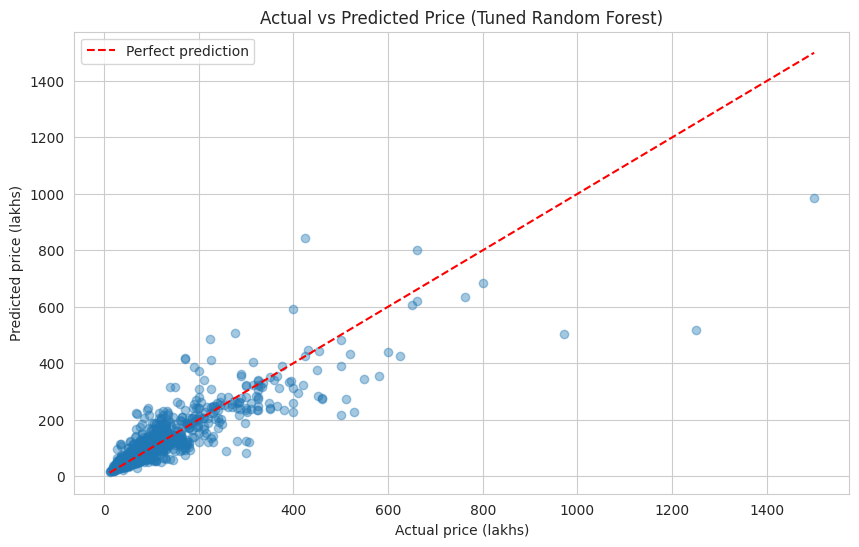

In [74]:
plt.scatter(y_test, test_pred, alpha=0.4)
line = [y_test.min(), y_test.max()]
plt.plot(line, line, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual price (lakhs)")
plt.ylabel("Predicted price (lakhs)")
plt.title("Actual vs Predicted Price (Tuned Random Forest)")
plt.legend()
plt.show()

**Actual vs Predicted insight:** Predictions follow the perfect-prediction line closely for homes below about 300 lakhs, where most of the data lies. For homes above about 500 lakhs the model consistently under-predicts (for example, an actual price of about 1,500 lakhs is predicted at about 980), because luxury homes are rare in the training data and tree models average toward typical prices. The model is therefore best used for typical homes, not luxury valuations.

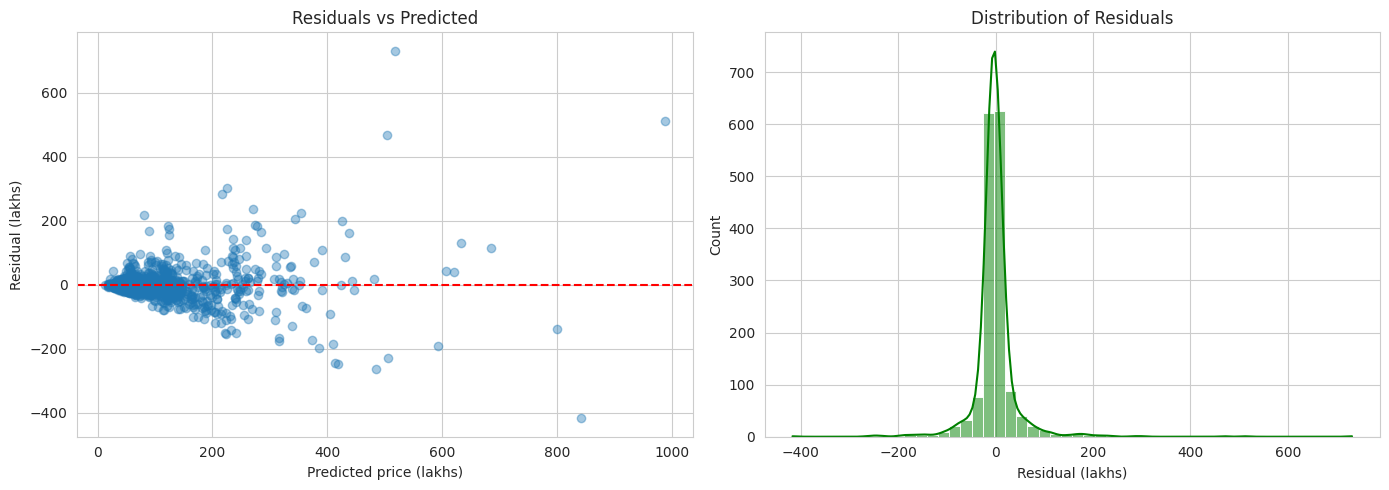

In [75]:
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(test_pred, residuals, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted price (lakhs)")
axes[0].set_ylabel("Residual (lakhs)")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="green")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (lakhs)")

plt.tight_layout()
plt.show()

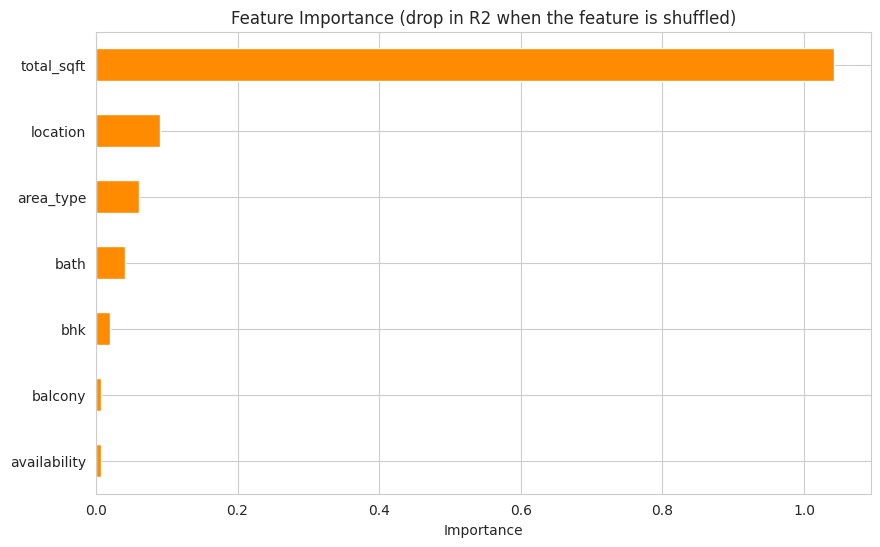

Top 5 features:
total_sqft    1.042
location      0.090
area_type     0.061
bath          0.042
bhk           0.020
dtype: float64


In [76]:
perm = permutation_importance(best_rf, X_test, y_test, n_repeats=5,
                              random_state=RANDOM_STATE, scoring="r2")

importance = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

importance.sort_values().plot(kind="barh", color="darkorange")
plt.title("Feature Importance (drop in R2 when the feature is shuffled)")
plt.xlabel("Importance")
plt.show()

print("Top 5 features:")
print(importance.head(5).round(3))

In [77]:
base = {"bath": 2, "balcony": 1, "bhk": 2,
        "area_type": df4["area_type"].mode()[0], "availability": "Ready To Move"}

print("1) Effect of area (Whitefield, 2 BHK):")
for sqft in [1000, 1100, 1200, 1300, 1400]:
    row = pd.DataFrame([{**base, "total_sqft": sqft, "location": "Whitefield"}])[feature_cols]
    print(f"   {sqft} sqft -> {best_rf.predict(row)[0]:.1f} lakhs")

print()
print("2) Effect of location (same 1200 sqft, 2 BHK home):")
for loc in ["Rajaji Nagar", "Indira Nagar", "Whitefield", "Electronic City", "other"]:
    row = pd.DataFrame([{**base, "total_sqft": 1200, "location": loc}])[feature_cols]
    print(f"   {loc:18s} -> {best_rf.predict(row)[0]:.1f} lakhs")

1) Effect of area (Whitefield, 2 BHK):
   1000 sqft -> 50.7 lakhs
   1100 sqft -> 58.3 lakhs
   1200 sqft -> 70.2 lakhs
   1300 sqft -> 81.5 lakhs
   1400 sqft -> 83.6 lakhs

2) Effect of location (same 1200 sqft, 2 BHK home):
   Rajaji Nagar       -> 120.5 lakhs
   Indira Nagar       -> 77.1 lakhs
   Whitefield         -> 70.2 lakhs
   Electronic City    -> 63.2 lakhs
   other              -> 63.2 lakhs


In [78]:
known_locations = set(df4["location"].unique())
area_lookup = {" ".join(a.split()): a for a in df4["area_type"].unique()}

def predict_price(location, total_sqft, bath, bhk, balcony=2,
                  area_type="Super built-up Area", availability="Ready To Move"):
    loc = location.strip()
    if loc not in known_locations:
        loc = "other"        # unseen locations are treated like rare ones
    area = area_lookup.get(" ".join(area_type.split()), df4["area_type"].mode()[0])

    row = pd.DataFrame([{
        "total_sqft": total_sqft, "bath": bath, "balcony": balcony, "bhk": bhk,
        "location": loc, "area_type": area, "availability": availability
    }])[feature_cols]
    return round(best_rf.predict(row)[0], 1)

print("2 BHK, 1200 sqft, Whitefield:    ", predict_price("Whitefield", 1200, 2, 2), "lakhs")
print("3 BHK, 1800 sqft, Indira Nagar:  ", predict_price("Indira Nagar", 1800, 3, 3), "lakhs")
print("1 BHK, 600 sqft, Electronic City:", predict_price("Electronic City", 600, 1, 1), "lakhs")

2 BHK, 1200 sqft, Whitefield:     68.4 lakhs
3 BHK, 1800 sqft, Indira Nagar:   163.4 lakhs
1 BHK, 600 sqft, Electronic City: 29.9 lakhs


In [79]:
joblib.dump(best_rf, "house_price_model.pkl")

from google.colab import files
files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Hyperparameter Tuning (Random Forest)
RandomizedSearchCV tried 12 combinations (3-fold CV on training data only).
Best settings: n_estimators=200, max_depth=15, min_samples_split=2, min_samples_leaf=2, max_features=0.5.

| Metric | Default | Tuned |
|---|---|---|
| Train R2 | 0.938 | 0.856 |
| Test R2 | 0.734 | 0.770 |
| RMSE | 51.18 | 47.58 |
| MAE | 21.80 | 22.13 |
| CV R2 | 0.672 | 0.694 |

Tuning raised Test R2 by 0.036 and cut RMSE by about 7%. The train/test gap fell from 0.204 to 0.086, so the tuned model overfits much less. MAE is 0.33 lakhs higher, which is negligible.

### Residual Analysis
- Residuals are centred around zero and most errors are small, so the model has no strong overall bias.
- Errors grow as the predicted price rises (funnel shape): the model is accurate for typical homes and weaker for luxury homes.
- The largest errors (about +730 and -415 lakhs) are a few luxury listings. Positive residuals are the bigger ones, meaning the model tends to under-predict very expensive homes.

### Top 5 Features Impacting Price (permutation importance)
1. total_sqft: by far the strongest driver (shuffling it ruins the model).
2. location: second; the same home costs about 1.9x more in Rajaji Nagar (120.5 lakhs) than in Electronic City (63.2 lakhs).
3. area_type: Plot Area homes are priced higher (see Plot 6).
4. bath
5. bhk
balcony and availability add almost nothing. Note: importance values are used for ranking only; total_sqft scores above 1.0 because shuffling it can make the model worse than predicting the average.

### Business Insights
- Size: in Whitefield, a 2 BHK goes from 50.7 lakhs at 1,000 sqft to 83.6 lakhs at 1,400 sqft, roughly 8 lakhs per extra 100 sqft on average.
- Location: for the same 1,200 sqft, 2 BHK home, predicted price is 120.5 lakhs in Rajaji Nagar, 77.1 in Indira Nagar, 70.2 in Whitefield and 63.2 in Electronic City.
- A buyer on a fixed budget gets noticeably more area in outer areas such as Electronic City, while central areas cost a premium for the same size.
- A builder or agent should price mainly by area first and location second; amenities like balcony and availability barely change price in this data.
- Typical error is about 22 lakhs (MAE), so the model is best used as a quick estimate for typical homes, not a valuation for luxury properties.

### Limitations
- Data is about 5 years old and prices are in lakhs of that period; they are listing prices, not final sale prices.
- Missing features: floor, building age, amenities, distance to metro/IT parks.
- About 37% of rows were removed as outliers, so the model is for typical homes, not extreme listings.
- Premium areas (e.g. Rajaji Nagar, Indira Nagar) look under-predicted compared with their average price per sqft.
- Luxury homes have the largest errors (residuals grow with price).
- Locations with 10 or fewer listings were grouped as "other".

### Conclusion
The tuned Random Forest was the best model (Test R2 0.770, RMSE 47.6 lakhs, MAE 22.1 lakhs, CV R2 0.694). It beat Linear Regression (Test R2 0.689) because the price-vs-size/BHK relationship is non-linear, and it avoided the heavy overfitting of a single Decision Tree. Log-transforming the price did not help.

In [80]:
import json

# the app's dropdown options
options = {
    "locations": sorted(df4["location"].unique().tolist()),
    "area_types": sorted(df4["area_type"].unique().tolist())
}
with open("locations.json", "w") as f:
    json.dump(options, f)

# model (same as Cell 94, safe to run again)
joblib.dump(best_rf, "house_price_model.pkl")

from google.colab import files
files.download("locations.json")
files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>